# Griffiths et al. 2021 — Breast Cancer · 02 Manifold
Fit a cell-state manifold to the Body compartment. Decide curve vs tree **from the embedding and a topology scan** (not a metric alone); root from the developmental signature order (Gast/pSom = origin, Crest = terminal); check for folds on an *independent* embedding.

In [1]:
%matplotlib inline
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('Body malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Body malignant manifold: 91802 cells
UMAP principal-axis ratio (major/minor singular value): 1.32
raw module means (honest readout): {'Gast': -0.02, 'pSom': -0.053, 'Crest': 0.0159}


### Signature geography on the whole Body (smoothed)
The module relationships tell us the topology to expect: co-varying Gast/pSom opposing Crest -> a single developmental axis (non-branching); a Gast vs pSom split diverging into two arms -> branching.

In [4]:
print('smoothed spatial correlations on the whole Body manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('cycling fraction: %.3f (single low-cycling body)' % adata.obs['cycling'].mean())
sub = adata

smoothed spatial correlations on the whole Body manifold:
  Gast_sm vs pSom_sm: r = -0.45
  Crest_sm vs Gast_sm: r = -0.28
  Crest_sm vs pSom_sm: r = -0.62
cycling fraction: 0.060 (single low-cycling body)


### Topology scan — curve vs tree
Fit principal curves across a node sweep and a PPT tree; count tips/forks and a fold self-approach ratio (min graph-distant node distance / median edge; >1 = fold-free). A branching manifold produces forks; a strip does not.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
a3 = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(a3, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=2000, ppt_sigma=0.5, seed=SEED, plot=False)
Bt = np.asarray(a3.uns['graph']['B'])
print(f'PPT tree N=20: {int(((Bt>0).sum(0)==1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} forks '
      f'({"0 forks -> non-branching" if int(((Bt>0).sum(0)>=3).sum())==0 else "forks -> candidate branching"})')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.98
curve N=20: 2 tips, 0 forks | self-approach 2.86
curve N=30: 2 tips, 0 forks | self-approach 2.34
PPT tree N=20: 7 tips, 5 forks (forks -> candidate branching)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.86 (>1 = fold-free)


### Root from the developmental signature order
Root at the curve tip that is Gast/pSom-high and Crest-low (the developmental origin); Crest is late/terminal.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for smod in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[smod]); print(f'  {smod}: rho={rho:+.3f} p={p:.1e}')
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
rho_c,_ = spearmanr(t, np.maximum(g1s, g2m))
print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} (axis is not proliferation-driven)')

tip 0: Gast=-0.0247 pSom=-0.0456 Crest=+0.0125
tip 2: Gast=-0.0210 pSom=-0.0591 Crest=+0.0205
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.011 p=1.3e-03
  pSom_sm: rho=-0.654 p=0.0e+00
  Crest_sm: rho=+0.565 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.85
Somitogenesis-high decile mean pseudotime = 0.12
Gastrulation-high decile mean pseudotime = 0.56
caveat: pseudotime vs cycling score rho = +0.07 (axis is not proliferation-driven)


### Orientation consistency
Orient the house linear layout so pseudotime increases left->right (origin left, terminus right).

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
print(f'corr(x_lin, pseudotime) = {r:+.2f} (origin on left, terminus on right)')
assert r > 0.3, f'orientation not pseudotime-consistent (corr={r:.2f})'

corr(x_lin, pseudotime) = +0.94 (origin on left, terminus on right)


In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', sub.shape)

saved manifold.h5ad (91802, 21353)


### Figure — pseudotime on the manifold

saved manifold.pdf


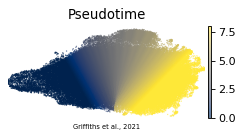

In [9]:
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=6, alpha=.6, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.pdf')